In [1]:
#input necessary functions
import os

import csv
import matplotlib.pyplot as plt
import numpy as np
import numpy #todo-redundant import
import pandas as pd
import random
import shutil
import torch
import xml.etree.ElementTree as ET

# Acquisition function
from botorch.acquisition import qLogExpectedImprovement
from botorch.sampling.stochastic_samplers import StochasticSampler
from botorch.utils.transforms import unnormalize
from botorch.optim import optimize_acqf

from skopt import gp_minimize
from skopt.plots import plot_convergence, plot_objective, plot_evaluations
from skopt.space import Real
from skopt.utils import use_named_args

#Sobol sequence generate initial locations
from torch.quasirandom import SobolEngine
from botorch.utils.transforms import unnormalize

### GP model surrogate
import gpytorch # todo:do we need full package import?
from botorch import fit_gpytorch_mll
from gpytorch.likelihoods import GaussianLikelihood
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.means.mean import Mean
from botorch.models import SingleTaskGP
from botorch.models.transforms import Standardize
from botorch.utils.transforms import normalize
from gpytorch.constraints import Interval
from gpytorch.kernels import MaternKernel, ScaleKernel, RBFKernel, Kernel, rbf_kernel

# we may no longer  need these
import math
from gpytorch.functions import MaternCovariance
from gpytorch.settings import trace_mode
import copy 

from modules.sumo import ErrorFunctionConnexionVersion,TLIncomingCorridors,CompleteCorridorsConnexions,ConnexionsGreenTime,connexions_routes_correspondance_matrix,update_green_time_dict,update_green_times,SumoSimulation
from modules.gp import UpdatedFAFunctionLinearRegresion,InitializeGPModel
from modules.bo import InitialSamples,Optimization,BOLoop
import ast


c:\Users\sh032\anaconda3\envs\thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Creation of the Ground Truth dataframe

In [ ]:
!python gt_dataset_generation_script.py

In [3]:
additional_xml = "ingolstadt7/additional.xml"
x_dim=7
gt_dir = 'gt_data/'
output_dir = 'outputs/'
init_output_dir="initial_output/"

scaling_loss_factor=1

num_replications = 5

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(x_dim))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

tl_ids = get_tls()
print(tl_ids)

df_gt = pd.read_csv(f'./gt_data/df_gt_InTAS7DIM.csv')
print(f'Number of GT connexions: {df_gt.shape[0]}')


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

x_bounds = torch.tensor([[low_bound]*x_dim,
                    [up_bound]*(x_dim-1)+[50]], 
                    device=device, dtype=dtype)

cfg_file="ingolstadt7/ingolstadt7.sumocfg"

sumo_simulator=SumoSimulation(
    cfg_file=cfg_file,
    output_dir=init_output_dir,
    tl_ids=tl_ids
)


net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

dtype=torch.double



corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}


complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)



error_function=ErrorFunctionConnexionVersion(scaling_factor_loss_fn=scaling_loss_factor,
                                         df_gt=df_gt,
                                         sumo_simulator=sumo_simulator,
                                         complete_corridors_connexions_df=complete_corridors_connexions_df,
                                         additional_xml=additional_xml,
                                         output_dir=init_output_dir,
                                         tl_ids=tl_ids)

initial_sampler=InitialSamples(
    objective_function=error_function,
    dtype=dtype
)

init_sample_x_norm = []
init_sample_y = []
init_df = []

num_restarts=3
init_sample_size=5

['gneJ260', 'gneJ210', '32564122', 'gneJ207', 'gneJ143', 'cluster_1757124350_1757124352', 'cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190']
Number of GT connexions: 81


In [ ]:
def average_route_traveltime(row,vehroute_df):
    route=row["route"]+[row["to_edge"]]
    route_str_str=" ".join(route)

    vehroute_df_route=vehroute_df[vehroute_df["route_str_str"].str.contains(route_str_str,regex=False)]


    if vehroute_df_route.empty:
        return np.nan

    def extract_times_index(vehroute_df_route_row,sub_route):
        full_route=vehroute_df_route_row["route"]
        start_indices = [i for i in range(len(full_route) - len(sub_route) + 1) if full_route[i:i+len(sub_route)] == sub_route]

        
        end_idices = [start_indx + len(sub_route) - 1 for start_indx in start_indices]

        return (start_indices,end_idices)

    vehroute_df_route["indices"]=vehroute_df_route.apply(extract_times_index,args=(route,),axis=1)

    vehroute_df_route["start_indices"] = vehroute_df_route["indices"].str[0]
    vehroute_df_route["end_indices"] = vehroute_df_route["indices"].str[1]

    vehroute_df_route["route_depart_times"]=vehroute_df_route.apply(
        lambda x : 
        [float(x["exit_times"][start_idx-1]) if start_idx>0 else float(x["depart"]) for start_idx in x["start_indices"]],
        axis=1)

    vehroute_df_route["route_exit_times"]=vehroute_df_route.apply(
        lambda x : [float(x["exit_times"][end_indx-1]) for end_indx in x["end_indices"]],
        axis=1)

    vehroute_df_route["route_traveltime"]=vehroute_df_route.apply(
        lambda x : [exit_time-depart_time for exit_time,depart_time in zip(x["route_exit_times"],x["route_depart_times"])],
        axis=1
    )


    traveltime_values=[tt for tt_list in vehroute_df_route["route_traveltime"].values for tt in tt_list]
    average_route_traveltime=np.mean(traveltime_values)


    if len(vehroute_df_route) == 0 or np.isnan(average_route_traveltime):
        print(f"connexion id : {row['connexion_id']}")
        print("Nombre de lignes :", len(vehroute_df_route))
        print("Average traveltime :",average_route_traveltime)
        print("-------------------------------------------------------------------")

    return average_route_traveltime
    


for n in range(10):


    tree = ET.parse(f"ingolstadt7/gt_data/gt_{n}_InTAS7DIM.vehroute.xml")
    root = tree.getroot()

    data = []

    for vehicle in root.findall("vehicle"):
        vehicle_id = vehicle.get("id")
        depart_tim=vehicle.get("depart")

        for route in vehicle.findall("route"):
            data.append({
                "vehicle_id": vehicle_id,
                "depart":vehicle.get("depart"),
                "route": route.get("edges").split(" "),
                "exit_times": [float(x) for x in route.get("exitTimes").split(" ")]
            })

    df = pd.DataFrame(data)

    df["route_str"]=df["route"].astype(str)
    df["route_str_str"]=df["route"].str.join(" ")
    df=df[~df["exit_times"].apply(lambda x : -1 in x)]

    complete_corridors_connexions_df["route_average_traveltime"]=complete_corridors_connexions_df.apply(average_route_traveltime,args=(df,),axis=1)
    print(f"rep : {n}")
    print(len(complete_corridors_connexions_df[complete_corridors_connexions_df["route_average_traveltime"].isna()]))
    display(complete_corridors_connexions_df.loc[complete_corridors_connexions_df["route_average_traveltime"].isna()][["connexion_id"]])
    print("======================================================================================")
    

In [14]:
display(complete_corridors_connexions_df[complete_corridors_connexions_df["connexion_id"]==37][["route_str_str","to_edge","link_index"]])

,route_str_str,to_edge,link_index
37,37386279 24634414#5 24634414#5.51 32999434#0,201089423#0,2


# Creation of the initial sample

In [2]:
additional_xml = "ingolstadt7/additional.xml"
x_dim=7
gt_dir = 'gt_data/'
output_dir = 'outputs/'
init_output_dir="initial_output/"

scaling_loss_factor=1

num_replications = 5

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(x_dim))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

tl_ids = get_tls()
print(tl_ids)

df_gt = pd.read_csv(f'./gt_data/df_gt_InTAS7DIM.csv')
df_gt["route"]=df_gt["route"].apply(lambda x : ast.literal_eval(x))
df_gt["green_phases"]=df_gt["green_phases"].apply(lambda x : ast.literal_eval(x))
print(f'Number of GT connexions: {df_gt.shape[0]}')


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

x_bounds = torch.tensor([[low_bound]*x_dim,
                    [up_bound]*(x_dim-1)+[50]], 
                    device=device, dtype=dtype)

cfg_file="ingolstadt7/ingolstadt7.sumocfg"

sumo_simulator=SumoSimulation(
    cfg_file=cfg_file,
    output_dir=init_output_dir,
    tl_ids=tl_ids
)


net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

dtype=torch.double



corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}


complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

torch.save(complete_corridors_connexions_df,"./corridors_savings/complete_corridors_connexions_df.pt")
torch.save(corridors_df,"./corridors_savings/corridors_df.pt")

error_function=ErrorFunctionConnexionVersion(scaling_factor_loss_fn=scaling_loss_factor,
                                         df_gt=df_gt,
                                         sumo_simulator=sumo_simulator,
                                         complete_corridors_connexions_df=complete_corridors_connexions_df,
                                         additional_xml=additional_xml,
                                         output_dir=init_output_dir,
                                         tl_ids=tl_ids)

initial_sampler=InitialSamples(
    objective_function=error_function,
    dtype=dtype
)


num_samples=3
init_sample_size=5

"""
for id_init_sample in range(num_samples):
    init_sample_x_norm, init_sample_y, init_df = initial_sampler.get_initial_sample(sample_size=init_sample_size,
                                                                     x_dim=x_dim,
                                                                     x_bounds=x_bounds,
                                                                     seed=id_init_sample,
                                                                     id_init_sample=id_init_sample,
                                                                     num_replications=num_replications)

    torch.save(init_sample_x_norm,f"./initial_samples/init_sample_x_norm_route_error_route_file_is{id_init_sample}.pt")
    torch.save(init_sample_y,f"./initial_samples/init_sample_y_route_error_route_file_is{id_init_sample}.pt")
    torch.save(init_df,f"./initial_samples/init_df_route_error_route_file_is{id_init_sample}.pt")
"""

['gneJ260', 'gneJ210', '32564122', 'gneJ207', 'gneJ143', 'cluster_1757124350_1757124352', 'cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190']
Number of GT connexions: 81


'\nfor id_init_sample in range(num_samples):\n    init_sample_x_norm, init_sample_y, init_df = initial_sampler.get_initial_sample(sample_size=init_sample_size,\n                                                                     x_dim=x_dim,\n                                                                     x_bounds=x_bounds,\n                                                                     seed=id_init_sample,\n                                                                     id_init_sample=id_init_sample,\n                                                                     num_replications=num_replications)\n\n    torch.save(init_sample_x_norm,f"./initial_samples/init_sample_x_norm_route_error_route_file_is{id_init_sample}.pt")\n    torch.save(init_sample_y,f"./initial_samples/init_sample_y_route_error_route_file_is{id_init_sample}.pt")\n    torch.save(init_df,f"./initial_samples/init_df_route_error_route_file_is{id_init_sample}.pt")\n'

In [5]:
additional_xml = "ingolstadt7/additional.xml"
x_dim=7
gt_dir = 'gt_data/'
output_dir = 'BO_outputs/'
init_output_dir="initial_output/"

df_gt=pd.read_csv("./gt_data/df_gt_InTAS7DIM.csv")

df_gt["route"]=df_gt["route"].apply(lambda x : ast.literal_eval(x))
df_gt["green_phases"]=df_gt["green_phases"].apply(lambda x : ast.literal_eval(x))


scaling_loss_factor=1

num_replications = 5

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(x_dim))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

tl_ids = get_tls()
print(tl_ids)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

x_bounds = torch.tensor([[low_bound]*x_dim,
                    [up_bound]*(x_dim-1)+[50]], 
                    device=device, dtype=dtype)

cfg_file="ingolstadt7/ingolstadt7.sumocfg"

sumo_simulator=SumoSimulation(
    cfg_file=cfg_file,
    output_dir=init_output_dir,
    tl_ids=tl_ids
)


net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

dtype=torch.double



corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}


complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)



error_function=ErrorFunctionConnexionVersion(scaling_factor_loss_fn=scaling_loss_factor,
                                         df_gt=df_gt,
                                         sumo_simulator=sumo_simulator,
                                         complete_corridors_connexions_df=complete_corridors_connexions_df,
                                         additional_xml=additional_xml,
                                         output_dir=init_output_dir,
                                         tl_ids=tl_ids)

initial_sampler=InitialSamples(
    objective_function=error_function,
    dtype=dtype
)

init_sample_x_norm = []
init_sample_y = []
init_df = []

num_restarts=1
init_sample_size=5




connexions_green_time_extractor=ConnexionsGreenTime(
    tl_ids=tl_ids,
    complete_corridors_connexions_df=df_gt,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=df_gt,
    connexions_green_time_extractor=connexions_green_time_extractor,
    dtype=dtype,
)


gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=x_bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

batch_size=1
num_restarts=3
raw_samples=128
niter=10
num_restarts_opti=5

optimizer=Optimization(batch_size=batch_size,
                       num_restarts_opti=num_restarts_opti,
                       device=device,
                       dtype=dtype,
                       raw_samples=raw_samples)



['gneJ260', 'gneJ210', '32564122', 'gneJ207', 'gneJ143', 'cluster_1757124350_1757124352', 'cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190']


In [ ]:
num_replications=5
for id_init_sample in range(3):
    init_df=torch.load(f"./initial_samples/init_df_route_error_route_file_is{id_init_sample}.pt",weights_only=False)
    bo_loop=BOLoop(niter=niter,
                    init_df=init_df,
                    gp_initializer=gp_initializer,
                    objective_function=error_function,
                    optimizer=optimizer,
                    dtype=dtype,
                    x_dim=x_dim,
                    loss_scale=scaling_loss_factor,
                    output_dir=output_dir,
                    bounds=x_bounds)
    for rs in range(3):
        bo_loop.run_loop(kernel_name="linear_regression",
                        mean_name="linear_regression",
                        annotation=f"nu_2.5_route_error_route_file_original_is{id_init_sample}",
                        rs=rs,
                        num_replications=num_replications)

In [ ]:
num_replications=5
for id_init_sample in range(3):
    init_df=torch.load(f"./initial_samples/init_df_route_error_route_file_is{id_init_sample}.pt",weights_only=False)
    bo_loop=BOLoop(niter=niter,
                    init_df=init_df,
                    gp_initializer=gp_initializer,
                    objective_function=error_function,
                    optimizer=optimizer,
                    dtype=dtype,
                    x_dim=x_dim,
                    loss_scale=scaling_loss_factor,
                    output_dir=output_dir,
                    bounds=x_bounds)
    for rs in range(3):
        bo_loop.run_loop(kernel_name="MaternKernel_default",
                        mean_name="ConstantMean",
                        annotation=f"nu_2.5_route_error_route_file_original_is{id_init_sample}",
                        rs=rs,
                        num_replications=num_replications)

#"MaternKernel_default"

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,592.308459,0.000000
1,0.0,331.538824,225.949287
2,1.0,326.788575,229.946996
3,2.0,191.983783,11.060065
4,3.0,191.983783,11.060065
5,4.0,191.983783,11.060065
6,5.0,191.983783,11.060065
7,6.0,191.983783,11.060065
8,7.0,191.983783,11.060065
9,8.0,191.983783,11.060065


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,592.308459,0.000000
1,0.0,592.308459,0.000000
2,1.0,592.308459,0.000000
3,2.0,592.308459,0.000000
4,3.0,592.308459,0.000000
5,4.0,522.878338,60.128249
6,5.0,379.203141,184.554619
7,6.0,379.203141,184.554619
8,7.0,318.930544,126.183654
9,8.0,318.930544,126.183654


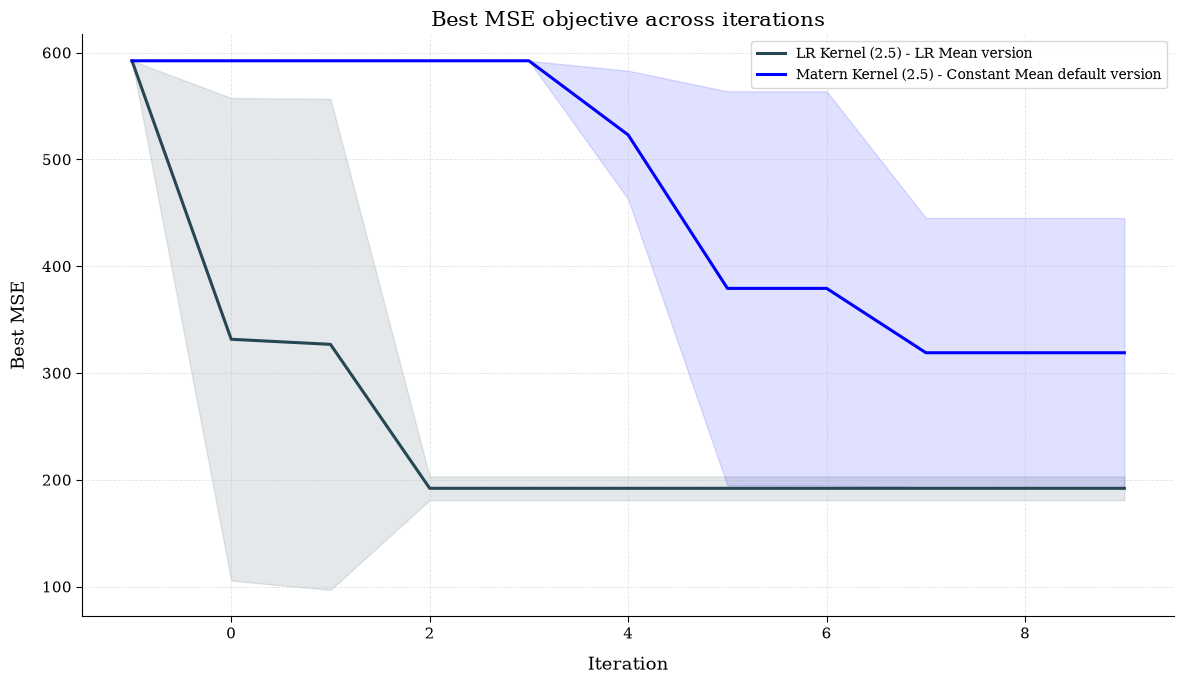

{'LR Kernel (2.5) - LR Mean version': (np.float64(191.98378316551057), np.float64(2.0)), 'Matern Kernel (2.5) - Constant Mean default version': (np.float64(318.9305441442685), np.float64(7.0))}


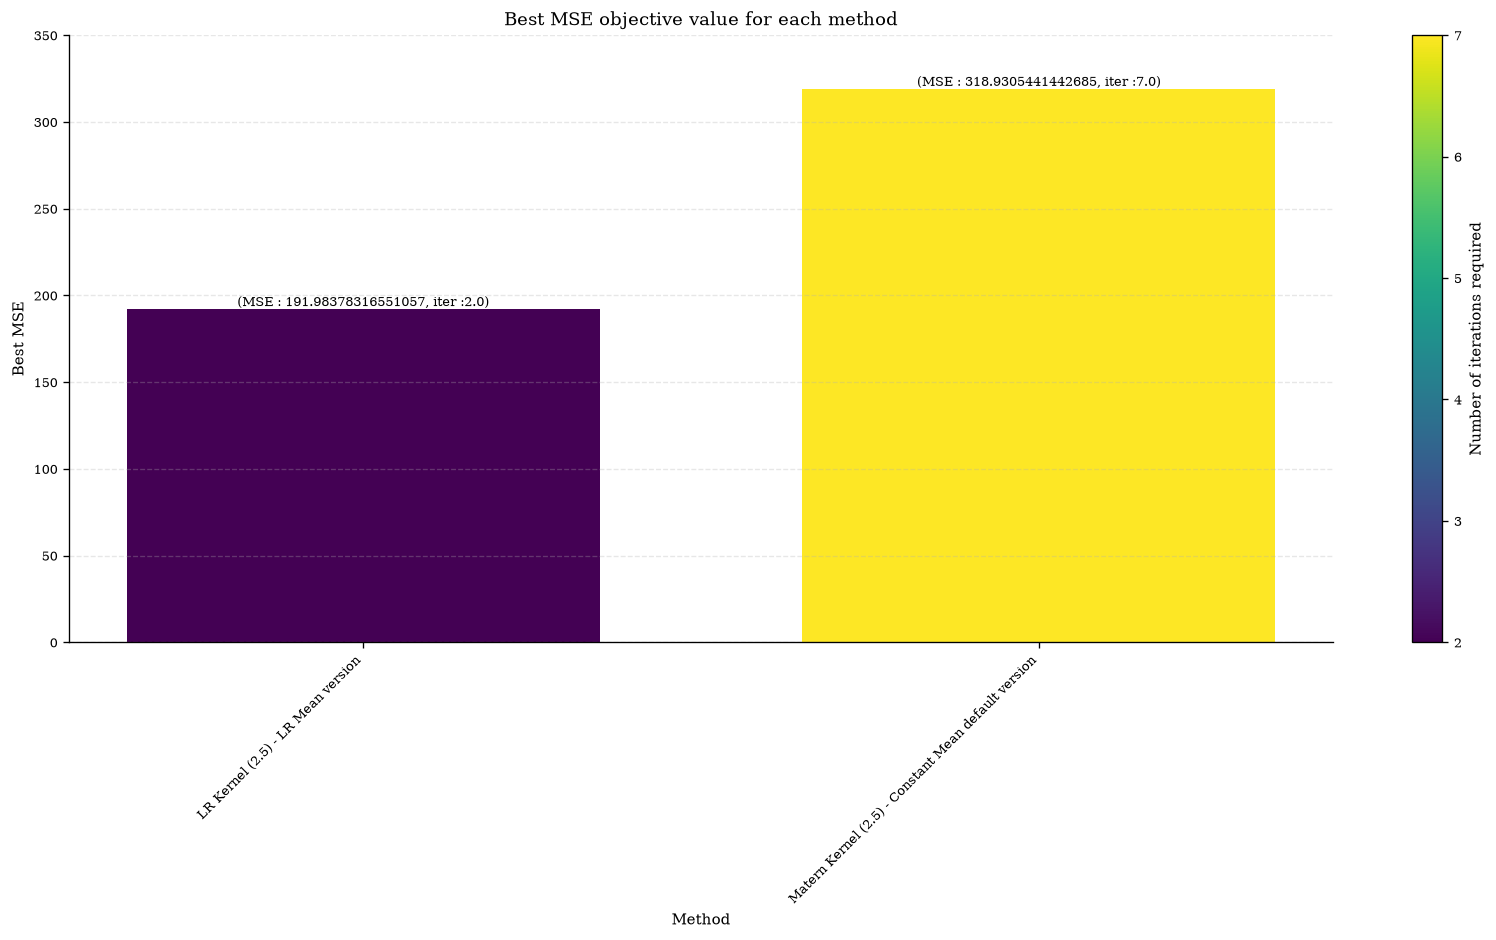

In [8]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(3):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["BO_outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is0_restart",
            "BO_outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_is0_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

print(version_min_values)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

for bar, iteration, min_value in zip(bars, iterations, min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value}, iter :{iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Number of iterations required", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,646.711628,0.000000
1,0.0,347.568877,259.273918
2,1.0,192.811439,4.691550
3,2.0,192.811439,4.691550
4,3.0,192.811439,4.691550
5,4.0,192.811439,4.691550
6,5.0,192.811439,4.691550
7,6.0,192.811439,4.691550
8,7.0,192.811439,4.691550
9,8.0,192.811439,4.691550


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,646.711628,0.000000
1,0.0,646.711628,0.000000
2,1.0,646.711628,0.000000
3,2.0,514.859443,114.218401
4,3.0,514.859443,114.218401
5,4.0,514.859443,114.218401
6,5.0,514.859443,114.218401
7,6.0,514.859443,114.218401
8,7.0,514.859443,114.218401
9,8.0,514.859443,114.218401


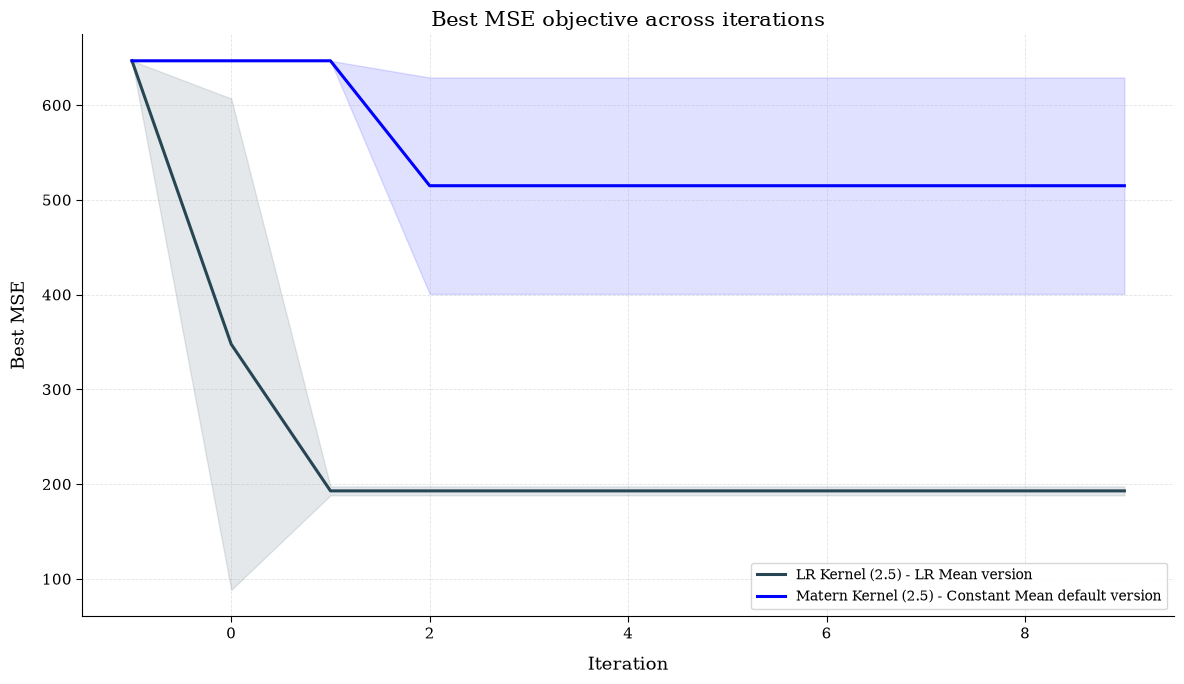

{'LR Kernel (2.5) - LR Mean version': (np.float64(192.8114385066682), np.float64(1.0)), 'Matern Kernel (2.5) - Constant Mean default version': (np.float64(514.8594426178821), np.float64(2.0))}


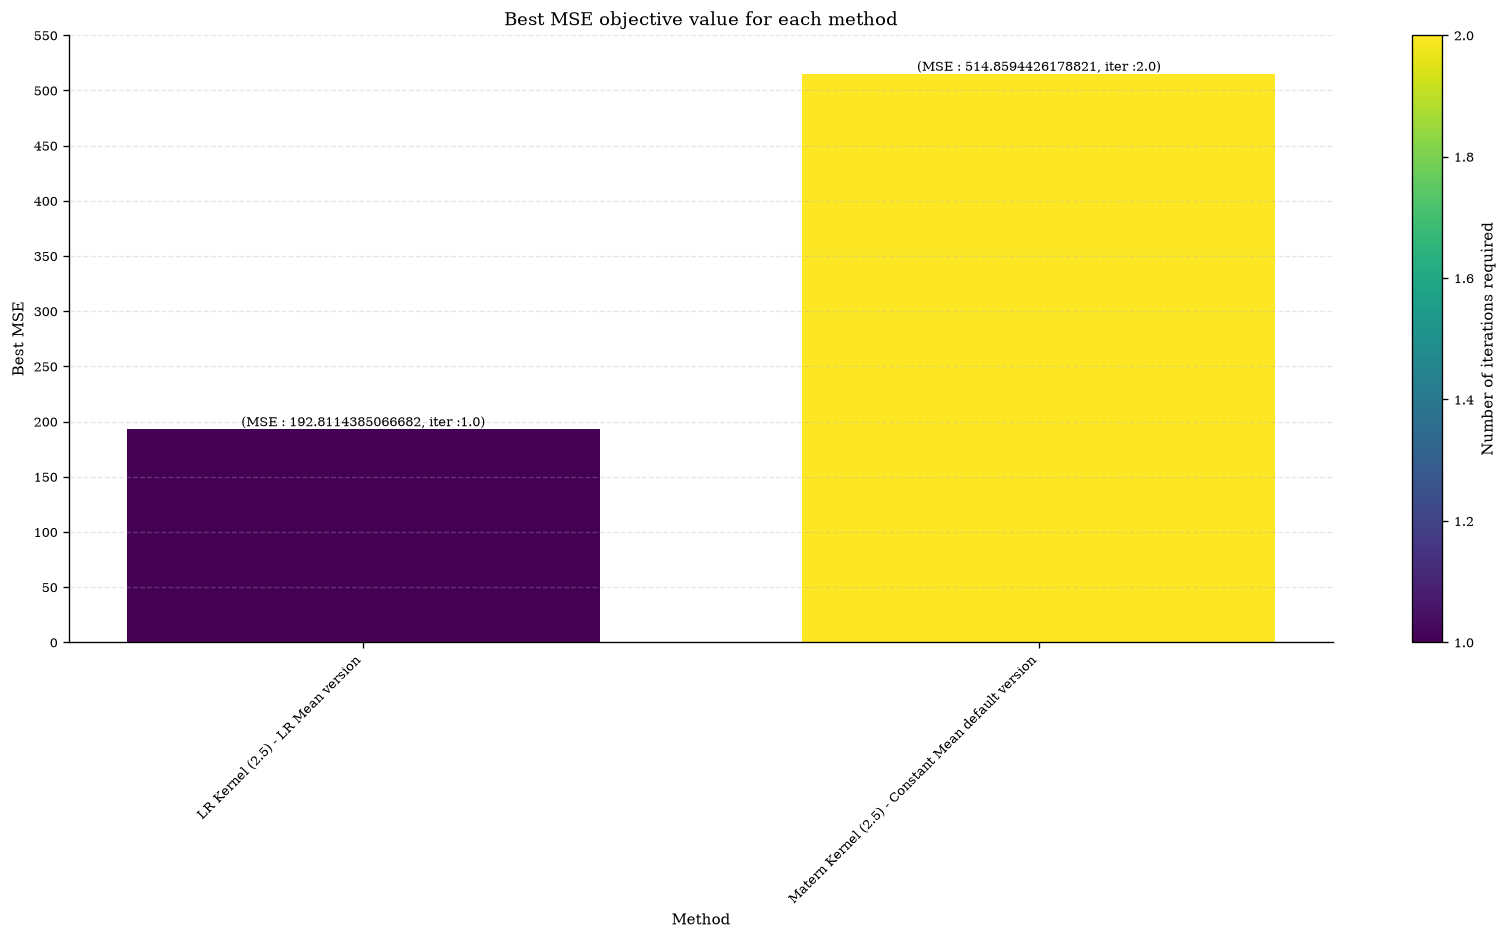

In [9]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(3):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["BO_outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is1_restart",
            "BO_outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_is1_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

print(version_min_values)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

for bar, iteration, min_value in zip(bars, iterations, min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value}, iter :{iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Number of iterations required", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,2831.797131,0.000000
1,0.0,1957.330825,1514.620071
2,1.0,194.530596,12.009710
3,2.0,193.199070,13.313514
4,3.0,193.199070,13.313514
5,4.0,193.199070,13.313514
6,5.0,193.199070,13.313514
7,6.0,193.199070,13.313514
8,7.0,193.199070,13.313514
9,8.0,193.199070,13.313514


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,2831.797131,0.000000
1,0.0,2658.317286,300.475905
2,1.0,2658.317286,300.475905
3,2.0,2334.773618,860.869977
4,3.0,1481.941145,1285.081095
5,4.0,1138.490752,1466.563507
6,5.0,1138.490752,1466.563507
7,6.0,411.274620,207.699986
8,7.0,307.140756,32.345247
9,8.0,307.140756,32.345247


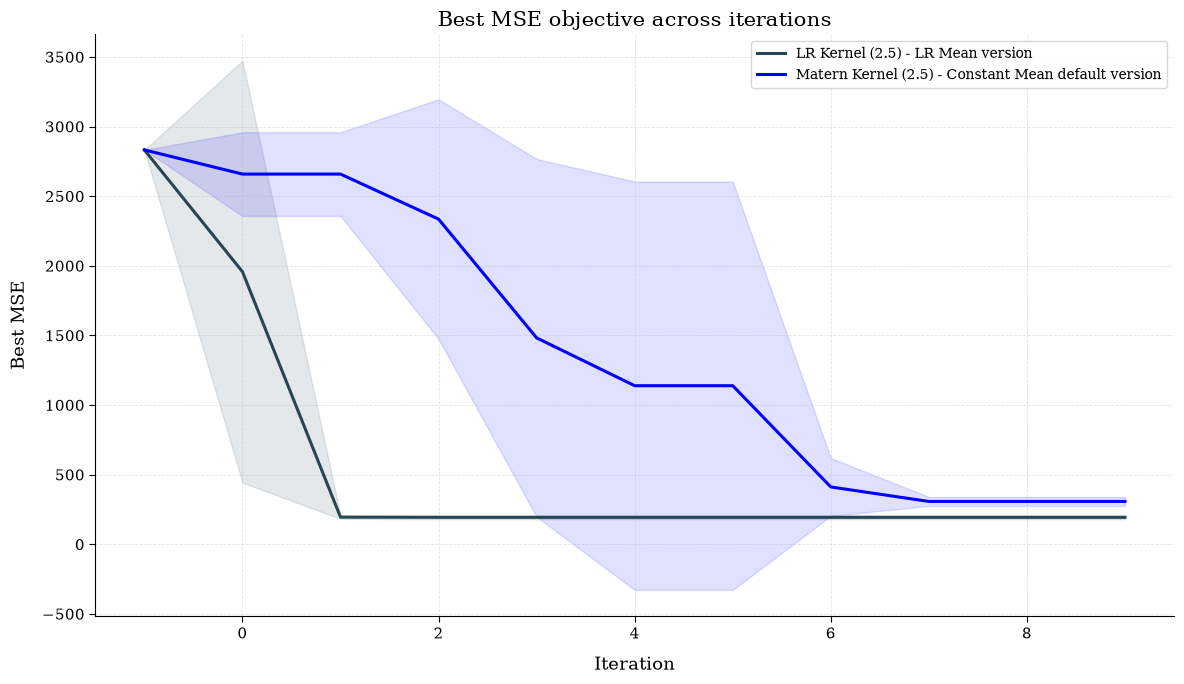

{'LR Kernel (2.5) - LR Mean version': (np.float64(193.19907028873914), np.float64(2.0)), 'Matern Kernel (2.5) - Constant Mean default version': (np.float64(307.14075554811944), np.float64(7.0))}


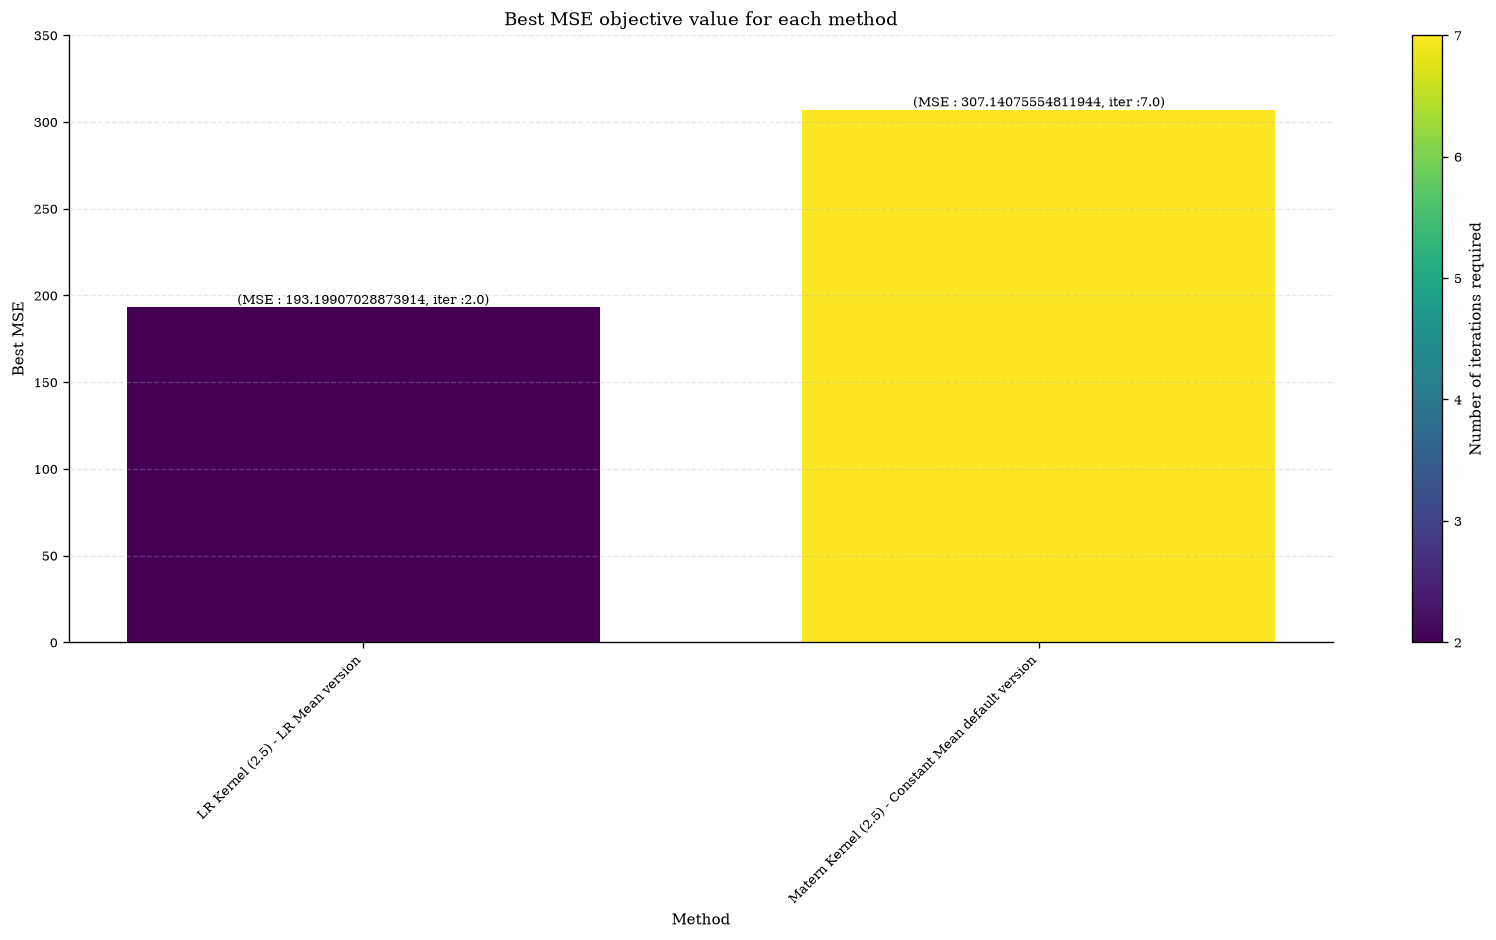

In [10]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(3):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["BO_outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is2_restart",
            "BO_outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_is2_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

print(version_min_values)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

for bar, iteration, min_value in zip(bars, iterations, min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value}, iter :{iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Number of iterations required", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()